In [1]:
# Cell 1: Import libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier

In [2]:
# Cell 2: Load dataset and inspect basic details

df = pd.read_csv("credit_card_fraud_10k.csv")

print("Shape of dataset:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget class distribution:")
print(df["is_fraud"].value_counts())

print("\nTarget class percentage:")
print(df["is_fraud"].value_counts(normalize=True) * 100)

Shape of dataset: (10000, 10)

Column names:
['transaction_id', 'amount', 'transaction_hour', 'merchant_category', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age', 'is_fraud']

First 5 rows:


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0



Data types:
transaction_id           int64
amount                 float64
transaction_hour         int64
merchant_category       object
foreign_transaction      int64
location_mismatch        int64
device_trust_score       int64
velocity_last_24h        int64
cardholder_age           int64
is_fraud                 int64
dtype: object

Missing values:
transaction_id         0
amount                 0
transaction_hour       0
merchant_category      0
foreign_transaction    0
location_mismatch      0
device_trust_score     0
velocity_last_24h      0
cardholder_age         0
is_fraud               0
dtype: int64

Target class distribution:
is_fraud
0    9849
1     151
Name: count, dtype: int64

Target class percentage:
is_fraud
0    98.49
1     1.51
Name: proportion, dtype: float64


Fraud percentage:
is_fraud
0    98.49
1     1.51
Name: proportion, dtype: float64


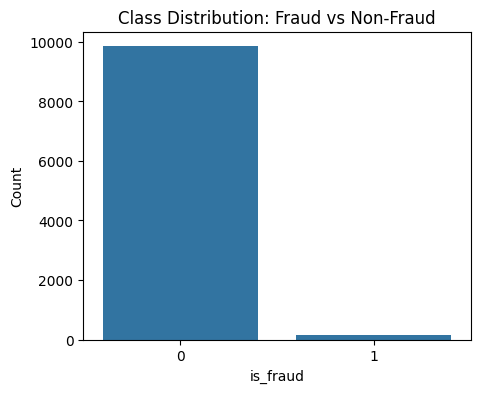

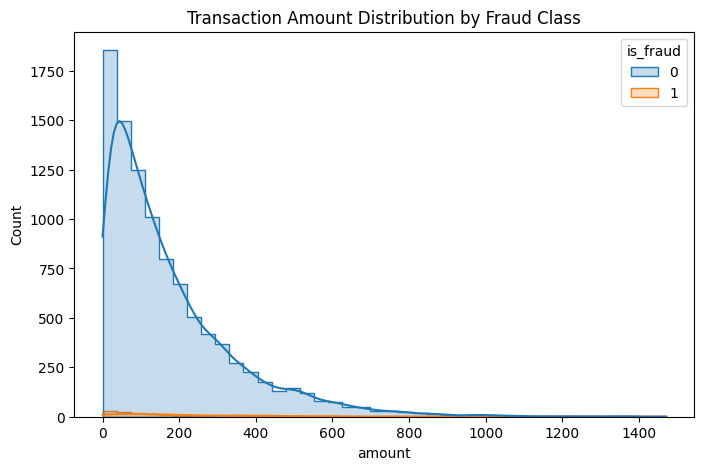

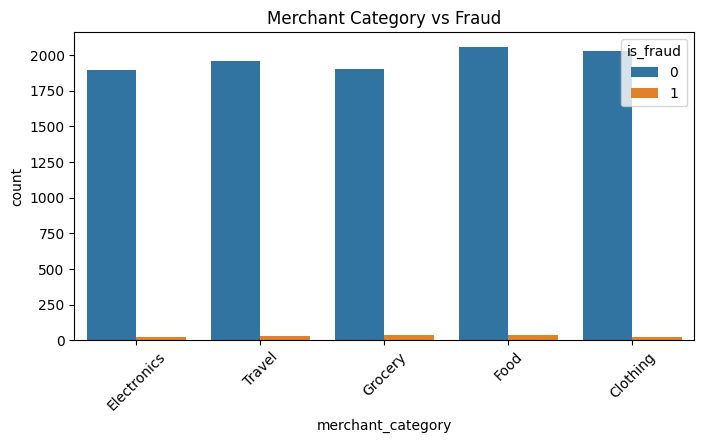

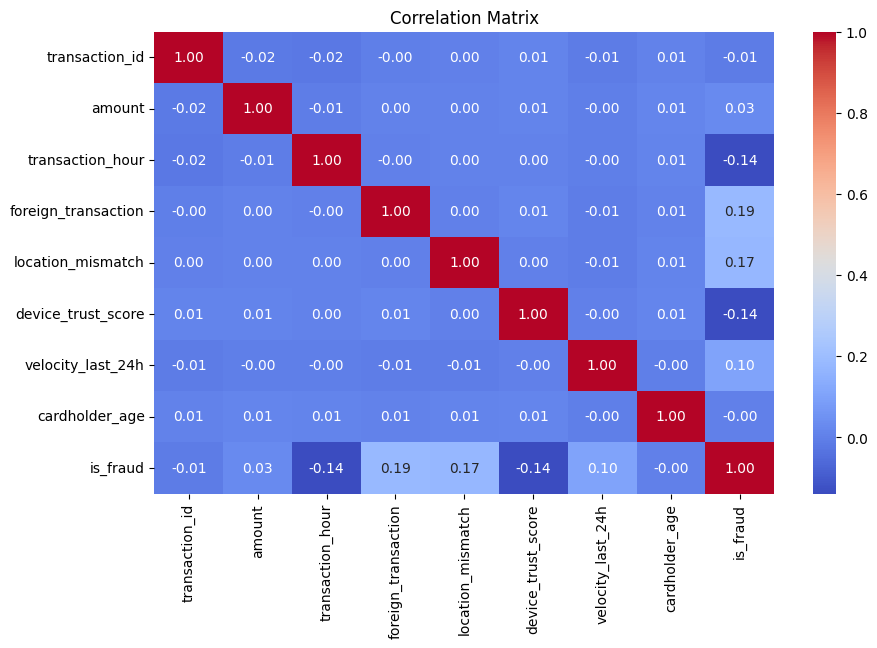

In [3]:
# Cell 3: Exploratory Data Analysis (EDA)

print("Fraud percentage:")
fraud_percent = df["is_fraud"].value_counts(normalize=True) * 100
print(fraud_percent)

plt.figure(figsize=(5, 4))
sns.countplot(x="is_fraud", data=df)
plt.title("Class Distribution: Fraud vs Non-Fraud")
plt.xlabel("is_fraud")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="amount", hue="is_fraud", bins=40, kde=True, element="step")
plt.title("Transaction Amount Distribution by Fraud Class")
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(x="merchant_category", hue="is_fraud", data=df)
plt.title("Merchant Category vs Fraud")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [4]:
# Cell 4: Define features and target

df = df.drop(columns=["transaction_id"])

X = df.drop("is_fraud", axis=1)
y = df["is_fraud"]

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

Categorical columns: ['merchant_category']
Numerical columns: ['amount', 'transaction_hour', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']

Feature matrix shape: (10000, 8)
Target vector shape: (10000,)


In [5]:
# Cell 5: Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train distribution:")
print(y_train.value_counts())

print("\ny_test distribution:")
print(y_test.value_counts())

X_train shape: (8000, 8)
X_test shape: (2000, 8)
y_train distribution:
is_fraud
0    7879
1     121
Name: count, dtype: int64

y_test distribution:
is_fraud
0    1970
1      30
Name: count, dtype: int64


In [6]:
# Cell 6: Preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [7]:
# Cell 7: Evaluation function

def evaluate_model(model, X_test, y_test, model_name="Model"):
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test)[:, 1]
    else:
        y_scores = y_pred

    print(f"\n{'='*50}")
    print(f"{model_name}")
    print(f"{'='*50}")

    print("Accuracy :", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
    print("F1-Score :", f1_score(y_test, y_pred, zero_division=0))
    print("ROC-AUC  :", roc_auc_score(y_test, y_scores))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))


Baseline Logistic Regression
Accuracy : 0.958
Precision: 0.25892857142857145
Recall   : 0.9666666666666667
F1-Score : 0.4084507042253521
ROC-AUC  : 0.9932825719120135

Confusion Matrix:
[[1887   83]
 [   1   29]]


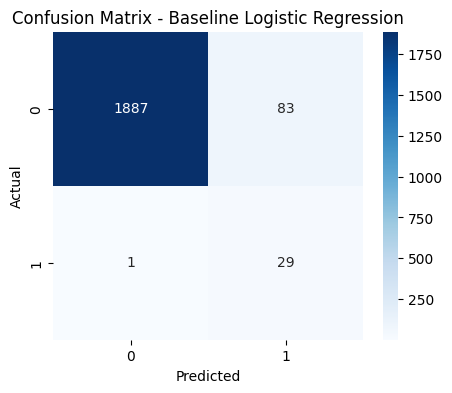


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      1970
           1       0.26      0.97      0.41        30

    accuracy                           0.96      2000
   macro avg       0.63      0.96      0.69      2000
weighted avg       0.99      0.96      0.97      2000



In [8]:
# Cell 8: Baseline Logistic Regression

log_reg_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000))
])

log_reg_model.fit(X_train, y_train)

evaluate_model(log_reg_model, X_test, y_test, "Baseline Logistic Regression")


Logistic Regression with SMOTE
Accuracy : 0.9635
Precision: 0.2871287128712871
Recall   : 0.9666666666666667
F1-Score : 0.44274809160305345
ROC-AUC  : 0.9932994923857867

Confusion Matrix:
[[1898   72]
 [   1   29]]


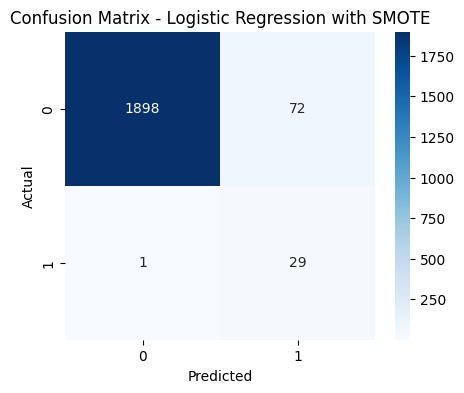


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      1970
           1       0.29      0.97      0.44        30

    accuracy                           0.96      2000
   macro avg       0.64      0.97      0.71      2000
weighted avg       0.99      0.96      0.97      2000



In [9]:
# Cell 9: Logistic Regression with SMOTE

smote_log_reg_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(random_state=42, max_iter=1000))
])

smote_log_reg_model.fit(X_train, y_train)

evaluate_model(smote_log_reg_model, X_test, y_test, "Logistic Regression with SMOTE")

In [10]:
# Cell 10: Install required packages (run only once if needed)

!pip install -q imbalanced-learn xgboost


Logistic Regression with Undersampling
Accuracy : 0.9505
Precision: 0.23255813953488372
Recall   : 1.0
F1-Score : 0.37735849056603776
ROC-AUC  : 0.994906937394247

Confusion Matrix:
[[1871   99]
 [   0   30]]


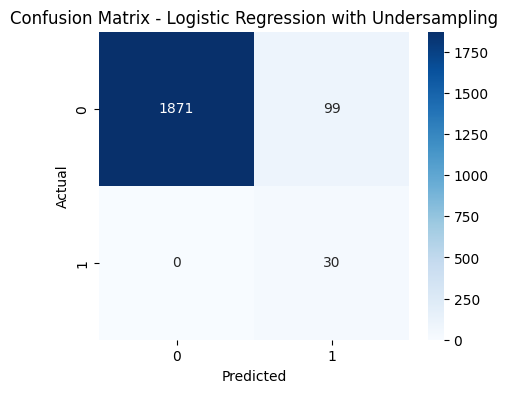


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97      1970
           1       0.23      1.00      0.38        30

    accuracy                           0.95      2000
   macro avg       0.62      0.97      0.68      2000
weighted avg       0.99      0.95      0.97      2000



In [11]:
# Cell 11: Logistic Regression with Random Undersampling

under_log_reg_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("undersampler", RandomUnderSampler(random_state=42)),
    ("classifier", LogisticRegression(random_state=42, max_iter=1000))
])

under_log_reg_model.fit(X_train, y_train)

evaluate_model(under_log_reg_model, X_test, y_test, "Logistic Regression with Undersampling")


Baseline Random Forest
Accuracy : 0.993
Precision: 1.0
Recall   : 0.5333333333333333
F1-Score : 0.6956521739130435
ROC-AUC  : 1.0

Confusion Matrix:
[[1970    0]
 [  14   16]]


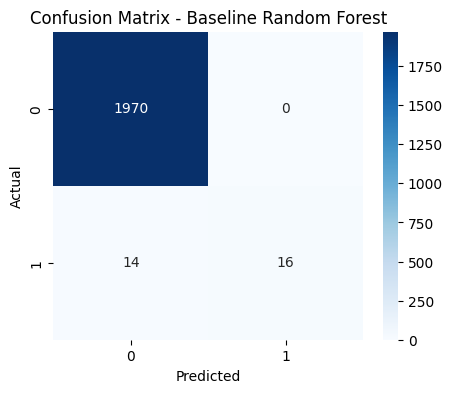


Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1970
           1       1.00      0.53      0.70        30

    accuracy                           0.99      2000
   macro avg       1.00      0.77      0.85      2000
weighted avg       0.99      0.99      0.99      2000



In [12]:
# Cell 12: Baseline Random Forest

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

evaluate_model(rf_model, X_test, y_test, "Baseline Random Forest")


Random Forest with SMOTE
Accuracy : 0.9945
Precision: 1.0
Recall   : 0.6333333333333333
F1-Score : 0.7755102040816326
ROC-AUC  : 0.9992554991539763

Confusion Matrix:
[[1970    0]
 [  11   19]]


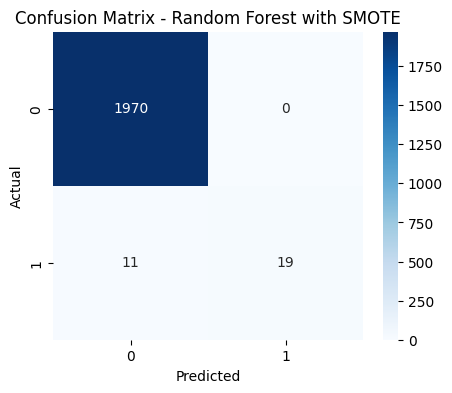


Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1970
           1       1.00      0.63      0.78        30

    accuracy                           0.99      2000
   macro avg       1.00      0.82      0.89      2000
weighted avg       0.99      0.99      0.99      2000



In [13]:
# Cell 13: Random Forest with SMOTE

smote_rf_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

smote_rf_model.fit(X_train, y_train)

evaluate_model(smote_rf_model, X_test, y_test, "Random Forest with SMOTE")


Random Forest with Undersampling
Accuracy : 0.917
Precision: 0.15306122448979592
Recall   : 1.0
F1-Score : 0.26548672566371684
ROC-AUC  : 0.9984940778341794

Confusion Matrix:
[[1804  166]
 [   0   30]]


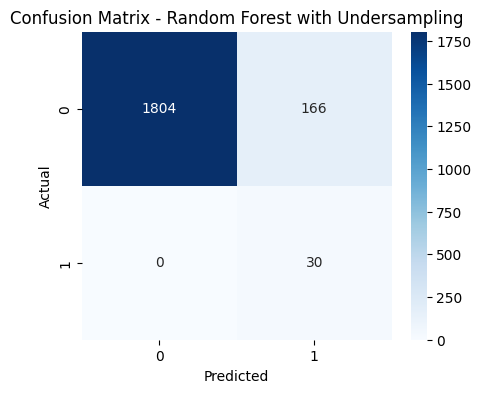


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96      1970
           1       0.15      1.00      0.27        30

    accuracy                           0.92      2000
   macro avg       0.58      0.96      0.61      2000
weighted avg       0.99      0.92      0.95      2000



In [14]:
# Cell 14: Random Forest with Random Undersampling

under_rf_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("undersampler", RandomUnderSampler(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

under_rf_model.fit(X_train, y_train)

evaluate_model(under_rf_model, X_test, y_test, "Random Forest with Undersampling")


Baseline XGBoost
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0
ROC-AUC  : 1.0

Confusion Matrix:
[[1970    0]
 [   0   30]]


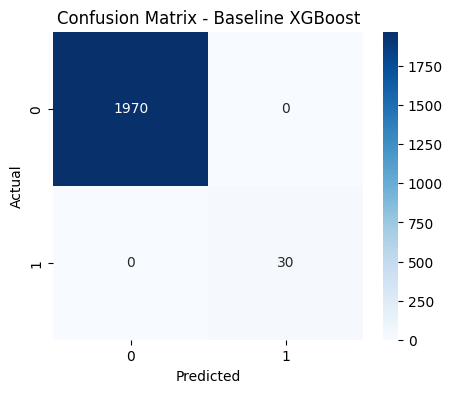


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1970
           1       1.00      1.00      1.00        30

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [15]:
# Cell 15: Baseline XGBoost

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=65,
        random_state=42,
        eval_metric="logloss"
    ))
])

xgb_model.fit(X_train, y_train)

evaluate_model(xgb_model, X_test, y_test, "Baseline XGBoost")


XGBoost with SMOTE
Accuracy : 0.9985
Precision: 0.9090909090909091
Recall   : 1.0
F1-Score : 0.9523809523809523
ROC-AUC  : 0.9999323181049069

Confusion Matrix:
[[1967    3]
 [   0   30]]


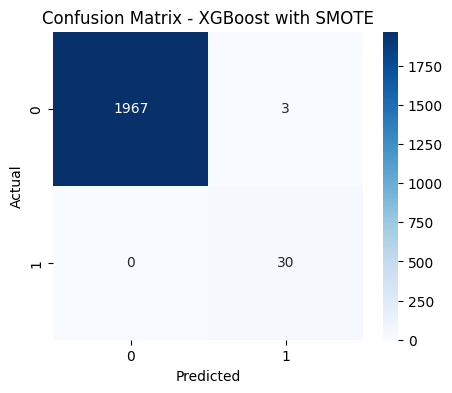


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1970
           1       0.91      1.00      0.95        30

    accuracy                           1.00      2000
   macro avg       0.95      1.00      0.98      2000
weighted avg       1.00      1.00      1.00      2000



In [16]:
# Cell 16: XGBoost with SMOTE

smote_xgb_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    ))
])

smote_xgb_model.fit(X_train, y_train)

evaluate_model(smote_xgb_model, X_test, y_test, "XGBoost with SMOTE")


XGBoost with Undersampling
Accuracy : 0.9525
Precision: 0.24
Recall   : 1.0
F1-Score : 0.3870967741935484
ROC-AUC  : 0.9998477157360406

Confusion Matrix:
[[1875   95]
 [   0   30]]


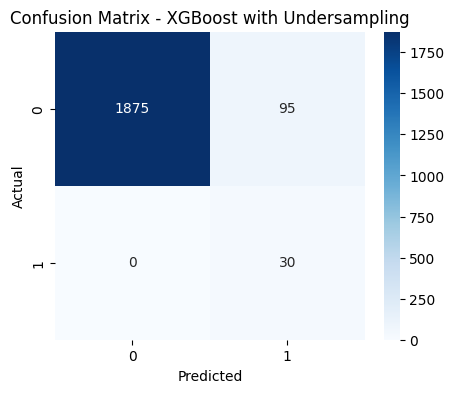


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98      1970
           1       0.24      1.00      0.39        30

    accuracy                           0.95      2000
   macro avg       0.62      0.98      0.68      2000
weighted avg       0.99      0.95      0.97      2000



In [17]:
# Cell 17: XGBoost with Random Undersampling

under_xgb_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("undersampler", RandomUnderSampler(random_state=42)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    ))
])

under_xgb_model.fit(X_train, y_train)

evaluate_model(under_xgb_model, X_test, y_test, "XGBoost with Undersampling")

In [18]:
# Cell 18: Prepare data for Isolation Forest

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape :", X_test_processed.shape)

Processed training shape: (8000, 12)
Processed testing shape : (2000, 12)



Isolation Forest
Accuracy : 0.9735
Precision: 0.20512820512820512
Recall   : 0.26666666666666666
F1-Score : 0.2318840579710145

Confusion Matrix:
[[1939   31]
 [  22    8]]


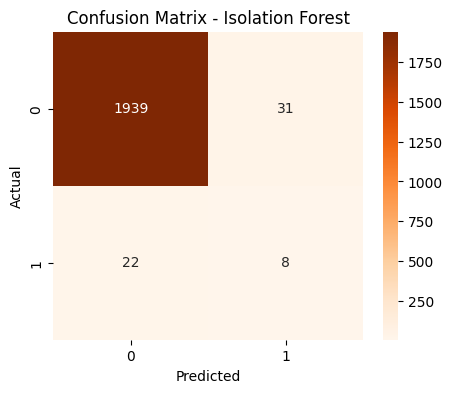


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1970
           1       0.21      0.27      0.23        30

    accuracy                           0.97      2000
   macro avg       0.60      0.63      0.61      2000
weighted avg       0.98      0.97      0.98      2000



In [19]:
# Cell 19: Isolation Forest model

iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.015,
    random_state=42
)

iso_forest.fit(X_train_processed)

iso_pred = iso_forest.predict(X_test_processed)

# Convert predictions: -1 -> 1 (fraud), 1 -> 0 (non-fraud)
iso_pred = np.where(iso_pred == -1, 1, 0)

print("\n" + "="*50)
print("Isolation Forest")
print("="*50)

print("Accuracy :", accuracy_score(y_test, iso_pred))
print("Precision:", precision_score(y_test, iso_pred, zero_division=0))
print("Recall   :", recall_score(y_test, iso_pred, zero_division=0))
print("F1-Score :", f1_score(y_test, iso_pred, zero_division=0))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, iso_pred)
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges")
plt.title("Confusion Matrix - Isolation Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, iso_pred, zero_division=0))

In [20]:
# Cell 20: Compare all models

results = []

def store_results(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_score)
    else:
        roc_auc = np.nan

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc
    })

store_results(log_reg_model, X_test, y_test, "Baseline Logistic Regression")
store_results(smote_log_reg_model, X_test, y_test, "Logistic Regression + SMOTE")
store_results(under_log_reg_model, X_test, y_test, "Logistic Regression + Undersampling")

store_results(rf_model, X_test, y_test, "Baseline Random Forest")
store_results(smote_rf_model, X_test, y_test, "Random Forest + SMOTE")
store_results(under_rf_model, X_test, y_test, "Random Forest + Undersampling")

store_results(xgb_model, X_test, y_test, "Baseline XGBoost")
store_results(smote_xgb_model, X_test, y_test, "XGBoost + SMOTE")
store_results(under_xgb_model, X_test, y_test, "XGBoost + Undersampling")

results.append({
    "Model": "Isolation Forest",
    "Accuracy": accuracy_score(y_test, iso_pred),
    "Precision": precision_score(y_test, iso_pred, zero_division=0),
    "Recall": recall_score(y_test, iso_pred, zero_division=0),
    "F1-Score": f1_score(y_test, iso_pred, zero_division=0),
    "ROC-AUC": np.nan
})

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline XGBoost,1.0000,1.000000,1.000000,1.000000,1.000000
1,XGBoost + SMOTE,0.9985,0.909091,1.000000,0.952381,0.999932
2,Random Forest + SMOTE,0.9945,1.000000,0.633333,0.775510,0.999255
3,Baseline Random Forest,0.9930,1.000000,0.533333,0.695652,1.000000
4,Logistic Regression + SMOTE,0.9635,0.287129,0.966667,0.442748,0.993299
5,Baseline Logistic Regression,0.9580,0.258929,0.966667,0.408451,0.993283
6,XGBoost + Undersampling,0.9525,0.240000,1.000000,0.387097,0.999848
7,Logistic Regression + Undersampling,0.9505,0.232558,1.000000,0.377358,0.994907
8,Random Forest + Undersampling,0.9170,0.153061,1.000000,0.265487,0.998494
9,Isolation Forest,0.9735,0.205128,0.266667,0.231884,NaN


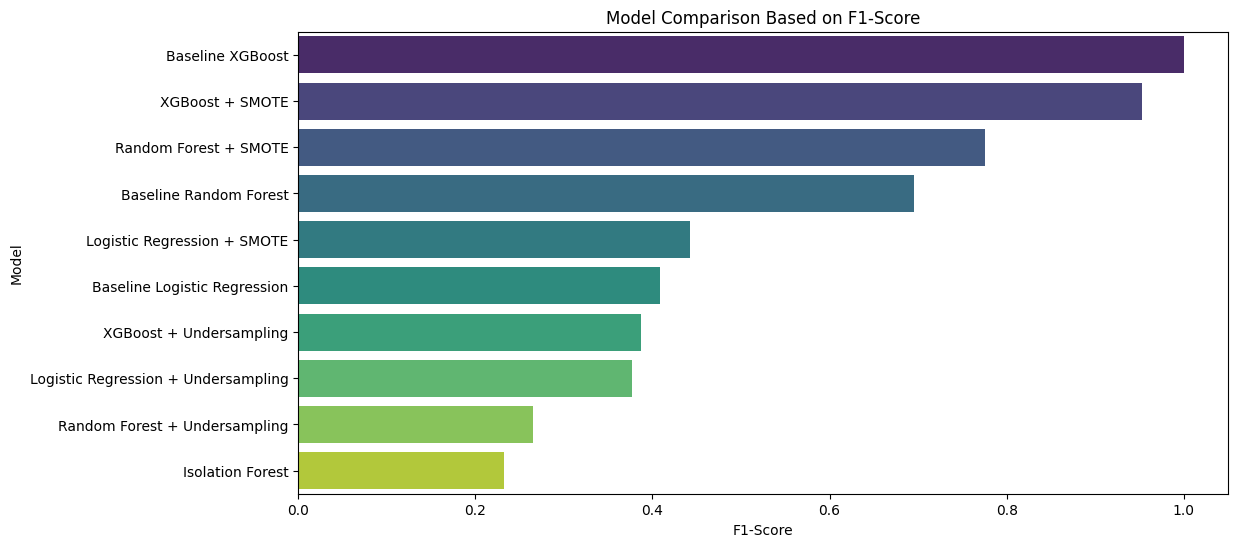

In [21]:
# Cell 21: Visualize model comparison

plt.figure(figsize=(12, 6))
sns.barplot(data=results_df, x="F1-Score", y="Model", palette="viridis")
plt.title("Model Comparison Based on F1-Score")
plt.xlabel("F1-Score")
plt.ylabel("Model")
plt.show()

In [22]:
# Cell 22: Final observations

best_model = results_df.iloc[0]

print("Final Observations")
print("=" * 60)
print(f"Total transactions: {len(df)}")
print(f"Fraud cases: {df['is_fraud'].sum()}")
print(f"Non-fraud cases: {(df['is_fraud'] == 0).sum()}")
print("\nBest model based on F1-Score:")
print(best_model)

print("\nConclusion:")
print("1. The dataset is highly imbalanced, so accuracy alone is not a reliable metric.")
print("2. SMOTE and undersampling help improve minority class learning.")
print("3. Tree-based models like Random Forest and XGBoost often perform better for fraud detection.")
print("4. Isolation Forest provides an anomaly detection approach without supervised labels.")
print("5. The best model can be selected based on F1-score and recall for fraud cases.")

Final Observations
Total transactions: 10000
Fraud cases: 151
Non-fraud cases: 9849

Best model based on F1-Score:
Model        Baseline XGBoost
Accuracy                  1.0
Precision                 1.0
Recall                    1.0
F1-Score                  1.0
ROC-AUC                   1.0
Name: 0, dtype: object

Conclusion:
1. The dataset is highly imbalanced, so accuracy alone is not a reliable metric.
2. SMOTE and undersampling help improve minority class learning.
3. Tree-based models like Random Forest and XGBoost often perform better for fraud detection.
4. Isolation Forest provides an anomaly detection approach without supervised labels.
5. The best model can be selected based on F1-score and recall for fraud cases.
